# 체크포인터와 스레드

**이 노트북에서 할 일**

1. 체크포인터 없이 두 번 실행한 그래프와, 체크포인터를 붙여 같은 스레드로 두 번 실행한 그래프를 견줍니다.
2. 저장된 상태와 체크포인트 목록을 읽어, 무엇이 몇 개 저장됐는지 셉니다.
3. 스레드 이름이나 입력 칸 하나를 바꿔, 스레드마다 상태가 따로 쌓이는 것을 확인합니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
그래서 `.env` 파일을 읽는 셀과 키를 확인하는 셀이 없습니다.
이 챕터는 상태를 저장하고 이어 가는 일이 주제입니다.
매번 같은 값을 내는 우리 노드로 그래프를 만들어야, 저장된 값이 맞는지 출력으로 가를 수 있습니다.

노트북은 빈 임시 폴더를 만들어 그 폴더에서 실행합니다.
이 절의 체크포인터는 파일을 쓰지 않고, 읽어 오는 자료 파일도 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 5초 안에 끝났습니다.
설치 셀에 걸리는 시간은 네트워크에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 둘을 설치합니다.
판은 langgraph 1.2.11과, 체크포인터가 들어 있는 langgraph-checkpoint 4.2.0입니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~8절을 읽습니다.
체크포인터를 붙이기 전과 뒤를 견주고, 저장된 것을 세는 자리입니다.
9~12절은 스레드 이름과 입력 칸을 바꿔 보는 자리이고, 실습 시간에 실행합니다.

실습 폴더 `labs/part6/ch23-persistence`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 내려가는 흐름도입니다. 맨 위 초록 상자 설정 딕셔너리 키 configurable 아래 thread_id에서 invoke의 둘째 인자라고 적힌 화살표가 회색 상자 그래프 graph 체크포인터를 붙여 컴파일로 갑니다. 그래프에서 단계를 마칠 때마다 저장이라고 적힌 화살표가 회색 상자 체크포인터 InMemorySaver 이 프로그램의 메모리에 저장으로 갑니다. 체크포인터에서 점선 두 갈래가 나가, thread_id가 customer-a이면 노란 상자 스레드 customer-a 체크포인트 여섯 합계 7로, thread_id가 customer-b이면 노란 상자 스레드 customer-b 체크포인트 셋 합계 4로 가는 그림](attachment:01-1-스레드마다-따로-쌓이는-체크포인트.png)

위에서 아래로 읽습니다.
초록 상자는 우리가 넘긴 값이고, 회색 상자는 라이브러리가 만든 그래프와 체크포인터입니다.
노란 상자는 노트북 8·9절에서 출력으로 확인한 값입니다.
체크포인터에서 나가는 두 점선은 스레드 이름에 따라 저장할 줄을 고르는 자리입니다.
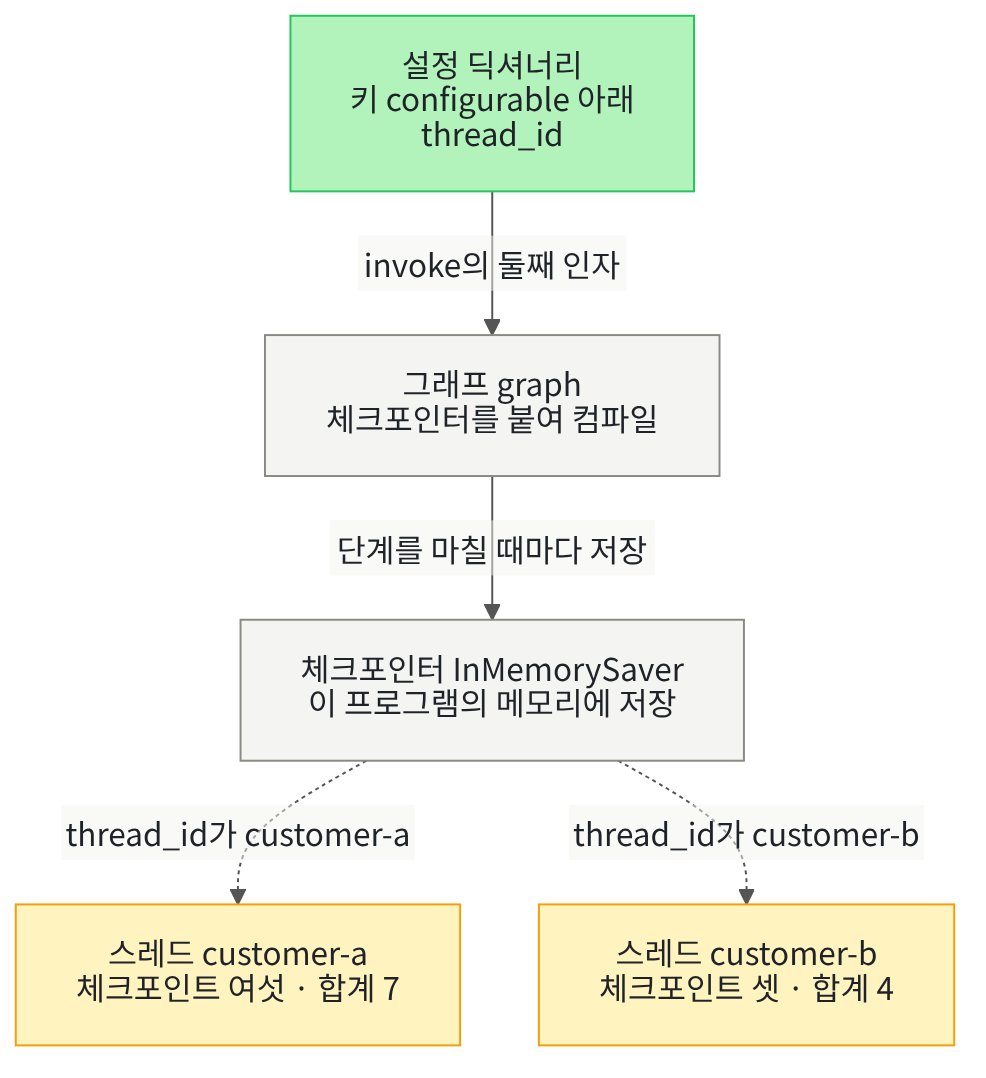

## 1. 준비

Ch 21까지의 그래프는 실행이 끝나면 상태를 따로 남기지 않았습니다.
이 챕터는 실행 중 상태를 저장해 두었다가, 다음 실행에서 이어 쓰는 법을 배웁니다.
챕터 제목의 Persistence는 실행이 끝난 뒤에도 상태를 남겨 두는 일(상태 저장)입니다.
제목의 Durable Execution은 멈춘 실행을 저장된 자리부터 다시 이어 가는 일(이어 실행)입니다.
이 절은 그 첫걸음으로, 상태를 저장하는 부품과 저장된 상태를 나누는 이름을 봅니다.

첫 셀은 패키지 둘을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langgraph==1.2.11" "langgraph-checkpoint==4.2.0"
from importlib.metadata import version

print("langgraph:", version("langgraph"))
print("langgraph-checkpoint:", version("langgraph-checkpoint"))

Note: you may need to restart the kernel to use updated packages.
langgraph: 1.2.11
langgraph-checkpoint: 4.2.0


**결과 읽기** — 출력 줄 `langgraph: 1.2.11`·`langgraph-checkpoint: 4.2.0`이 보입니다.
두 판 모두 실습 폴더 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-25에 이 판으로 실행한 결과입니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
상태 형식과 그래프를 만드는 이름은 Ch 13 01·02절과 같습니다.
새로 가져오는 이름은 체크포인터 `InMemorySaver` 하나이고, 뜻은 4절에서 풉니다.
모델을 부르지 않는 절이라, Ch 20 03절처럼 모델과 메시지 이름은 가져오지 않습니다.

In [2]:
# 상태 형식과 그래프를 만들 이름(Ch 13 01·02절)과, 체크포인터 하나를 가져옵니다
import operator
from typing import Annotated
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END
# 체크포인트를 이 프로그램의 메모리에 담아 두는 체크포인터입니다
from langgraph.checkpoint.memory import InMemorySaver

print("이 절에서 새로 가져온 이름:", "InMemorySaver")

이 절에서 새로 가져온 이름: InMemorySaver


**결과 읽기** — 출력 줄 `이 절에서 새로 가져온 이름: InMemorySaver`가 보입니다.
이 이름은 모듈 `langgraph.checkpoint.memory`에 있고, 첫 셀에서 설치한 langgraph-checkpoint에 들어 있습니다.

다음 셀은 Ch 4 03절처럼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다.
이 챕터의 뒤 절들은 체크포인트를 파일에 씁니다.
실습 폴더에 파일을 남기지 않으려고, 모든 절이 이 모양으로 빈 임시 폴더에서 시작합니다.
이 절의 체크포인터는 파일을 쓰지 않는데, 11절에서 폴더가 그대로 비어 있는지 봅니다.

폴더 위치는 컴퓨터마다 달라 출력하지 않고, 폴더 이름에 붙인 앞머리만 확인합니다.
모듈 `os`와 `tempfile`은 Python에 들어 있는 기능 묶음입니다.

In [3]:
# 파일이 생기는지 볼 빈 임시 폴더를 만들고, 그 폴더로 작업 위치를 옮깁니다(Ch 4 03절과 같은 모양)
import os
import tempfile

# mkdtemp()는 운영체제 임시 폴더 안에 새 폴더를 만들고, 그 폴더의 위치를 글로 내놓습니다
practice_folder = tempfile.mkdtemp(prefix="ch23-01-")
# chdir()는 터미널의 cd처럼 현재 작업 폴더를 옮깁니다
os.chdir(practice_folder)
print("임시 폴더 이름에 ch23-01-이 들어 있는가:", "ch23-01-" in practice_folder)
print("현재 작업 폴더의 파일:", os.listdir())

임시 폴더 이름에 ch23-01-이 들어 있는가: True
현재 작업 폴더의 파일: []


**결과 읽기** — 출력 줄 `임시 폴더 이름에 ch23-01-이 들어 있는가: True`로, 이 절의 폴더를 만들었습니다.
출력 줄 `현재 작업 폴더의 파일: []`로, 빈 폴더에서 시작합니다.

## 2. 상태 형식과 노드

이 절의 그래프는 수를 이어 더하는 작은 그래프입니다.
다음 셀은 상태 형식입니다.
칸 `total`은 지금까지의 합계, 칸 `amount`는 이번에 더할 수입니다.
칸 `trace`는 Ch 13 01절의 실행 흔적이고, 이 칸에만 Ch 13 02절 규칙 `operator.add`를 적습니다.
나머지 두 칸은 규칙이 없어, 새 값이 오면 덮어씁니다.

In [4]:
# 합계·이번 수·실행 흔적 칸을 둔 상태 형식을 만듭니다(실행 흔적 칸에만 Ch 13 02절 이어 붙이기 규칙)
class CountState(TypedDict):
    total: int
    amount: int
    trace: Annotated[list[str], operator.add]

**결과 읽기** — 정의 셀이라 출력이 없습니다.
상태 형식 이름은 Ch 13 약속대로 칸 구성에 맞춰 새로 붙인 `CountState`입니다.

다음 셀은 노드 함수입니다.
합계 칸에 이번 수를 더한 값과, 실행 흔적에 넣을 자기 이름 `"add"`를 냅니다.

In [5]:
# 합계 칸에 이번 수를 더한 값과, 실행 흔적에 넣을 자기 이름을 냅니다
def add_amount(state):
    new_total = state["total"] + state["amount"]
    # 규칙을 적은 실행 흔적 칸에는 자기 몫 한 칸만 냅니다(Ch 13 02절)
    return {"total": new_total, "trace": ["add"]}

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `add_amount`는 칸 `amount`를 읽기만 하고, 갱신에는 넣지 않습니다.

Ch 13 01절처럼 다음 셀은 이 노드 함수를 그래프 없이 직접 불러 봅니다.
손으로 만든 상태의 합계는 3, 이번 수는 4입니다.

In [6]:
# 노드 함수도 보통 함수입니다. 손으로 만든 상태를 넣어 그래프 없이 직접 불러 봅니다
hand_state = {"total": 3, "amount": 4, "trace": ["add"]}
hand_update = add_amount(hand_state)
print("add_amount가 낸 갱신:", hand_update)

add_amount가 낸 갱신: {'total': 7, 'trace': ['add']}


**결과 읽기** — 출력 줄 `add_amount가 낸 갱신: {'total': 7, 'trace': ['add']}`입니다.
합계 3에 4를 더한 7과, 실행 흔적 한 칸이 갱신에 들어 있습니다.
노드 함수는 받은 상태만 보고 계산하므로, 같은 상태를 넣으면 늘 같은 갱신을 냅니다.

## 3. 체크포인터 없이 두 번 실행하기

먼저 Ch 13 01절 모양 그대로, 체크포인터 없이 그래프를 만듭니다.
다음 셀은 노드 하나와 엣지 둘을 설계 객체에 적고 컴파일합니다.
마지막 줄은 그래프에 체크포인터가 붙었는지 봅니다.

In [7]:
# 노드 하나와 엣지 둘을 설계 객체에 적고, 먼저 체크포인터 없이 컴파일합니다(Ch 13 01절 모양)
builder = StateGraph(CountState)
builder.add_node("add", add_amount)
builder.add_edge(START, "add")
builder.add_edge("add", END)
plain_graph = builder.compile()
print("컴파일 결과의 종류:", type(plain_graph).__name__)
# 속성 checkpointer에는 그래프에 붙은 체크포인터가 들어 있습니다
print("붙은 체크포인터:", plain_graph.checkpointer)

컴파일 결과의 종류: CompiledStateGraph
붙은 체크포인터: None


**결과 읽기** — 출력 줄 `컴파일 결과의 종류: CompiledStateGraph`는 Ch 13 01절과 같습니다.
출력 줄 `붙은 체크포인터: None`으로, 이 그래프에는 체크포인터가 없습니다.
값 `None`은 Python에서 「값이 없음」을 뜻합니다.

다음 셀은 합계 0과 이번 수 3을 넣어 실행합니다.

In [8]:
# 체크포인터 없는 그래프에 합계 0과 이번 수 3을 넣어 실행합니다
plain_first = plain_graph.invoke({"total": 0, "amount": 3, "trace": []})
print("첫 실행 결과:", plain_first)

첫 실행 결과: {'total': 3, 'amount': 3, 'trace': ['add']}


**결과 읽기** — 출력 줄 `첫 실행 결과: {'total': 3, 'amount': 3, 'trace': ['add']}`입니다.
합계 칸이 0에서 3이 되었고, 실행 흔적에 `add`가 한 칸 남았습니다.

다음 셀은 같은 그래프에 이번 수 4만 넣어 다시 실행합니다.
실행 전에 예상해 봅니다.
앞 실행의 합계 3이 남아 있다면 7이 나올 것입니다.
이 셀만 올라온 오류를 받아 출력하고, 셀은 끝까지 갑니다.
오류를 받는 `try`·`except`는 Ch 2 05절에서 배웠습니다.

In [9]:
# 같은 그래프에 이번 수 4만 넣어 다시 실행합니다(이 셀만 올라온 오류를 받아 출력합니다)
try:
    plain_graph.invoke({"amount": 4})
except KeyError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: KeyError
오류 글: 'total'


**결과 읽기** — 출력 줄 `받은 오류: KeyError`와 `오류 글: 'total'`입니다.
노드 함수가 칸 `total`을 찾았는데, 상태에 그 칸이 없었다는 뜻입니다.
둘째 실행은 넣은 칸 `amount` 하나만 가진 상태에서 시작했습니다.
체크포인터가 없는 그래프는 실행이 끝나면 상태를 남기지 않기 때문입니다.
Ch 21 03절에서도 결과 상태는 실행 한 번 안에서만 보았습니다.

## 4. 체크포인터를 붙여 컴파일하기

체크포인터(checkpointer)는 그래프가 단계를 하나 마칠 때마다 그때의 상태를 저장해 두는 부품입니다.
체스 판을 한 수마다 사진으로 찍어 두는 카메라와 사진첩에 견줄 수 있습니다.
이 절에서는 클래스 `InMemorySaver`로 만든 체크포인터를, 메서드 `compile`의 인자 `checkpointer`로 넘깁니다.
단계는 Ch 20 03절에서 본, 그래프가 노드를 골라 한 번 실행하는 차례입니다.

클래스 `InMemorySaver`는 저장한 것을 이 Python 프로그램(커널)의 메모리에 둡니다.
다음 셀은 체크포인터를 만들고, 3절의 설계 객체를 이 체크포인터와 함께 다시 컴파일합니다.
설계 객체는 그대로이고, 컴파일할 때 넘긴 인자 하나만 다릅니다.

In [10]:
# 체크포인터 하나를 만들고, 3절의 설계 객체를 이 체크포인터와 함께 다시 컴파일합니다
memory = InMemorySaver()
graph = builder.compile(checkpointer=memory)
print("체크포인터의 종류:", type(memory).__name__)
print("붙은 체크포인터의 종류:", type(graph.checkpointer).__name__)

체크포인터의 종류: InMemorySaver
붙은 체크포인터의 종류: InMemorySaver


**결과 읽기** — 출력 줄 `체크포인터의 종류: InMemorySaver`입니다.
출력 줄 `붙은 체크포인터의 종류: InMemorySaver`로, 새 그래프에 이 체크포인터가 붙었습니다.
이름 `graph`가 체크포인터를 붙인 그래프이고, `plain_graph`는 3절의 체크포인터 없는 그래프입니다.

## 5. 스레드 이름과 첫 실행

스레드(thread)는 한 이름으로 묶인 체크포인트들의 줄입니다.
판 하나 앞에 그 판의 사진만 모아 둔 것과 같습니다.
스레드 이름은 설정 딕셔너리에 적어, 메서드 `invoke`의 둘째 인자로 넘깁니다.
설정 딕셔너리는 Ch 20 03절에서 실행 한도 `recursion_limit`을 적은 그 딕셔너리입니다.
이번에는 키 `configurable` 아래에 딕셔너리를 하나 더 두고, 그 안에 스레드 이름 `thread_id`를 적습니다.

In [11]:
# 설정 딕셔너리의 키 configurable 아래에 스레드 이름 thread_id를 적습니다
config_a = {"configurable": {"thread_id": "customer-a"}}
print("스레드 customer-a의 설정:", config_a)

스레드 customer-a의 설정: {'configurable': {'thread_id': 'customer-a'}}


**결과 읽기** — 출력 줄 `스레드 customer-a의 설정: {'configurable': {'thread_id': 'customer-a'}}`입니다.
스레드 이름은 우리가 정하는 글이고, 이 절에서는 `customer-a`로 정했습니다.
설정 딕셔너리는 상태에 들어가지 않습니다.

다음 셀은 이 설정으로 첫 실행을 합니다.
입력은 3절 첫 실행과 같은 합계 0과 이번 수 3입니다.

In [12]:
# 스레드 customer-a로 첫 실행을 합니다(입력은 3절 첫 실행과 같음)
first_result = graph.invoke({"total": 0, "amount": 3, "trace": []}, config_a)
print("첫 실행 결과:", first_result)

첫 실행 결과: {'total': 3, 'amount': 3, 'trace': ['add']}


**결과 읽기** — 출력 줄 `첫 실행 결과: {'total': 3, 'amount': 3, 'trace': ['add']}`는 3절 첫 실행과 같습니다.
체크포인터를 붙여도 한 번의 실행 결과는 달라지지 않았습니다.
달라진 것은 이 실행의 상태가 스레드 `customer-a`에 저장된 것이고, 7·8절에서 읽습니다.

## 6. 같은 스레드로 한 번 더 실행하기

다음 셀은 3절 둘째 실행처럼 이번 수 4만 넣고, 같은 설정 `config_a`로 실행합니다.
실행 전에 예상해 봅니다.
체크포인터가 스레드 `customer-a`의 마지막 상태를 꺼내 오면, 합계 3에 4를 더해 7이 될 것입니다.
셀 끝 `assert`는 실행마다 같아야 하는 합계에만 겁니다.

In [13]:
# 같은 스레드로 이번 수 4만 넣어 다시 실행합니다(입력은 3절 둘째 실행과 같음)
second_result = graph.invoke({"amount": 4}, config_a)
print("둘째 실행 결과:", second_result)
# 저장된 합계 3에서 이어 가므로, 실행마다 같아야 하는 값입니다
assert second_result["total"] == 7, "같은 스레드의 둘째 실행은 합계 7이어야 합니다"

둘째 실행 결과: {'total': 7, 'amount': 4, 'trace': ['add', 'add']}


**결과 읽기** — 출력 줄 `둘째 실행 결과: {'total': 7, 'amount': 4, 'trace': ['add', 'add']}`입니다.
합계가 저장된 3에서 이어져 7이 되었고, 3절에서 받은 `KeyError`는 나지 않았습니다.
실행 흔적 칸은 첫 실행의 `add` 뒤에 둘째 실행의 `add`가 붙어 두 칸입니다.
넣은 칸 `amount`는 4로 바뀌었고, 넣지 않은 칸 `total`은 저장된 값에서 시작했습니다.

## 7. 저장된 상태 읽기

메서드 `get_state`는 설정 딕셔너리를 받아, 그 스레드의 마지막 체크포인트를 객체 하나로 내놓습니다.
그 객체의 속성 `values`는 저장된 칸 값이고, `next`는 다음에 실행할 노드 이름들입니다.
속성 `metadata`는 체크포인트에 붙은 정보이고, 키 `step`에 단계 번호가 들어 있습니다.

In [14]:
# 스레드 customer-a의 마지막 체크포인트를 읽습니다(get_state는 체크포인트 하나를 담은 객체를 내놓음)
saved_a = graph.get_state(config_a)
print("읽은 것의 종류:", type(saved_a).__name__)
print("저장된 칸 값:", saved_a.values)
print("다음에 실행할 노드:", saved_a.next)
print("단계 번호:", saved_a.metadata["step"])

읽은 것의 종류: StateSnapshot
저장된 칸 값: {'total': 7, 'amount': 4, 'trace': ['add', 'add']}
다음에 실행할 노드: ()
단계 번호: 4


**결과 읽기** — 출력 줄 `읽은 것의 종류: StateSnapshot`입니다.
출력 줄 `저장된 칸 값: {'total': 7, 'amount': 4, 'trace': ['add', 'add']}`는 6절 둘째 실행 결과와 같습니다.
출력 줄 `다음에 실행할 노드: ()`는 빈 튜플이라, 이어서 실행할 노드가 없다는 뜻입니다.
출력 줄 `단계 번호: 4`는 다음 8절 목록의 맨 위 줄과 같은 번호입니다.

## 8. 체크포인트 목록 세기

체크포인트(checkpoint)는 체크포인터가 한 번 저장한 상태 하나입니다.
사진첩의 사진 한 장과 같습니다.
메서드 `get_state_history`는 한 스레드의 체크포인트를 최신 것부터 차례로 내놓습니다.
내놓은 것을 함수 `list`로 목록에 담으면 수를 셀 수 있습니다.

다음 셀은 체크포인트 목록을 받아 한 줄씩 출력하는 함수입니다.
한 줄에는 단계 번호, 만든 자리(키 `source`), 다음 노드, 칸 값을 적습니다.
목록의 항목은 7절에서 읽은 객체와 같은 종류입니다.

In [15]:
# 체크포인트 목록을 받아, 하나마다 단계 번호·만든 자리·다음 노드·칸 값을 한 줄로 출력합니다(내놓는 값 없음)
def print_history(history):
    print("단계 번호 | 만든 자리 | 다음 노드 | 칸 값")
    for snapshot in history:
        step = snapshot.metadata["step"]
        source = snapshot.metadata["source"]
        print(step, "|", source, "|", snapshot.next, "|", snapshot.values)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `print_history`는 인자로 받은 목록만 읽고, 노트북의 다른 이름에 기대지 않습니다.

다음 셀은 스레드 `customer-a`의 체크포인트 목록을 받아 수를 세고, 이 함수로 봅니다.
실행 전에 예상해 봅니다.
실행을 두 번 했으니, 체크포인트도 둘 이상일 것입니다.
셀 끝 `assert`는 실행마다 같아야 하는 체크포인트 수에만 겁니다.

In [16]:
# 스레드 customer-a의 체크포인트 목록을 받아 수를 세고, 한 줄씩 봅니다(목록은 최신 것부터)
history_a = list(graph.get_state_history(config_a))
print("customer-a의 체크포인트 수:", len(history_a))
print_history(history_a)
# 실행 두 번에 셋씩이라, 실행마다 같아야 하는 수입니다
assert len(history_a) == 6, "customer-a의 체크포인트는 여섯이어야 합니다"

customer-a의 체크포인트 수: 6
단계 번호 | 만든 자리 | 다음 노드 | 칸 값
4 | loop | () | {'total': 7, 'amount': 4, 'trace': ['add', 'add']}
3 | loop | ('add',) | {'total': 3, 'amount': 4, 'trace': ['add']}
2 | input | ('__start__',) | {'total': 3, 'amount': 3, 'trace': ['add']}
1 | loop | () | {'total': 3, 'amount': 3, 'trace': ['add']}
0 | loop | ('add',) | {'total': 0, 'amount': 3, 'trace': []}
-1 | input | ('__start__',) | {'trace': []}


**결과 읽기** — 출력 줄 `customer-a의 체크포인트 수: 6`입니다.
라벨 줄 `단계 번호 | 만든 자리 | 다음 노드 | 칸 값` 아래 여섯 줄이 최신 것부터 놓였습니다.
맨 아래 줄 `-1 | input | ('__start__',) | {'trace': []}`는 첫 입력을 받은 때의 체크포인트입니다.
맨 위 줄은 7절에서 읽은 마지막 체크포인트이고, 단계 번호가 `4`입니다.

한 번 실행할 때마다 체크포인트가 셋씩 쌓였습니다.
첫 실행은 단계 -1·0·1, 둘째 실행은 단계 2·3·4입니다.
셋은 입력을 받은 때, 입력을 칸에 넣은 뒤, 노드 `add`를 마친 뒤입니다.
입력을 받은 때의 체크포인트는 첫 단계 0보다 앞이라, 번호가 -1입니다.
만든 자리는 첫째가 `input`이고, 나머지 둘이 `loop`입니다.

단계 2 줄의 칸 값은 둘째 입력을 넣기 전 값이라, 이번 수가 아직 3입니다.
다음 노드 `__start__`는 Ch 13 01절의 가상 시작점이고, 입력을 칸에 넣을 차례라는 뜻입니다.

## 9. 값 바꿔 보기 · 스레드 이름만 바꾸기

바꿀 값은 설정 딕셔너리의 스레드 이름 하나입니다.
이번 수는 6절 둘째 실행과 같은 4를 넣습니다.
새 스레드에는 저장된 합계가 없어, 3절처럼 오류가 나지 않게 합계 0도 함께 넣습니다.
실행 전에 예상해 봅니다.
스레드 `customer-b`는 스레드 `customer-a`의 합계 7을 읽지 않아, 결과 합계가 4일 것입니다.

In [17]:
# 값 바꿔 보기: 스레드 이름만 customer-b로 바꾸고, 새 스레드라 합계 0부터 넣습니다
config_b = {"configurable": {"thread_id": "customer-b"}}
other_result = graph.invoke({"total": 0, "amount": 4, "trace": []}, config_b)
print("customer-b 실행 결과:", other_result)

customer-b 실행 결과: {'total': 4, 'amount': 4, 'trace': ['add']}


**결과 읽기** — 출력 줄 `customer-b 실행 결과: {'total': 4, 'amount': 4, 'trace': ['add']}`입니다.
합계가 0에서 시작해 4가 되었고, 실행 흔적도 한 칸입니다.
같은 그래프 `graph`와 같은 체크포인터를 썼지만, 스레드 `customer-a`의 값은 섞이지 않았습니다.

다음 셀은 스레드 `customer-b`의 체크포인트 수와, 스레드 `customer-a`의 마지막 합계를 다시 봅니다.

In [18]:
# 스레드 customer-b의 체크포인트 수와, customer-a의 마지막 합계를 다시 봅니다
history_b = list(graph.get_state_history(config_b))
print("customer-b의 체크포인트 수:", len(history_b))
again_a = graph.get_state(config_a)
print("customer-a의 마지막 합계:", again_a.values["total"])

customer-b의 체크포인트 수: 3
customer-a의 마지막 합계: 7


**결과 읽기** — 출력 줄 `customer-b의 체크포인트 수: 3`으로, 실행 한 번의 체크포인트 셋입니다.
출력 줄 `customer-a의 마지막 합계: 7`로, 스레드 `customer-b`를 실행한 뒤에도 그대로입니다.
체크포인터 하나가 스레드 이름마다 체크포인트 줄을 따로 두었습니다.

다음 셀은 한 번도 실행하지 않은 스레드 이름 `customer-new`로 마지막 체크포인트를 읽어 봅니다.

In [19]:
# 한 번도 실행하지 않은 스레드 이름으로 마지막 체크포인트를 읽어 봅니다
config_new = {"configurable": {"thread_id": "customer-new"}}
empty_state = graph.get_state(config_new)
print("저장된 칸 값:", empty_state.values)
print("다음에 실행할 노드:", empty_state.next)

저장된 칸 값: {}
다음에 실행할 노드: ()


**결과 읽기** — 출력 줄 `저장된 칸 값: {}`과 `다음에 실행할 노드: ()`입니다.
체크포인트가 없는 스레드는 빈 딕셔너리를 내놓았고, 오류는 나지 않았습니다.
그래서 스레드 이름을 잘못 적으면, 오류 없이 빈 상태를 읽게 됩니다.

## 10. 값 바꿔 보기 · 둘째 입력에 합계 칸도 넣기

6절에서 넣지 않은 칸 `total`은 저장된 값에서 시작했습니다.
이번에는 둘째 실행 입력에 합계 칸도 넣으면 어떻게 되는지 봅니다.
다음 셀은 새 스레드 `customer-c`에 먼저 스레드 `customer-a` 첫 실행과 같은 입력을 넣습니다.

In [20]:
# 값 바꿔 보기: 새 스레드 customer-c에 customer-a 첫 실행과 같은 입력을 넣습니다
config_c = {"configurable": {"thread_id": "customer-c"}}
third_first = graph.invoke({"total": 0, "amount": 3, "trace": []}, config_c)
print("customer-c 첫 실행 결과:", third_first)

customer-c 첫 실행 결과: {'total': 3, 'amount': 3, 'trace': ['add']}


**결과 읽기** — 출력 줄 `customer-c 첫 실행 결과: {'total': 3, 'amount': 3, 'trace': ['add']}`는 5절 첫 실행과 같습니다.

바꿀 값은 둘째 실행 입력에 더한 합계 칸 `total` 0 하나입니다.
실행 전에 예상해 봅니다.
Ch 13 02절에서 본 것처럼, 규칙 없는 칸은 새로 들어온 값으로 덮어씁니다.
체크포인터가 저장된 합계 3을 꺼내 와도, 입력의 0이 그 값을 덮어쓸 것입니다.
그러면 합계는 0에 4를 더한 4가 되고, 실행 흔적 칸은 두 칸이 될 것입니다.

In [21]:
# 둘째 실행 입력에 합계 칸 total 0도 함께 넣습니다(customer-a 둘째 실행과 다른 값은 이것 하나)
third_second = graph.invoke({"total": 0, "amount": 4}, config_c)
print("customer-c 둘째 실행 결과:", third_second)

customer-c 둘째 실행 결과: {'total': 4, 'amount': 4, 'trace': ['add', 'add']}


**결과 읽기** — 출력 줄 `customer-c 둘째 실행 결과: {'total': 4, 'amount': 4, 'trace': ['add', 'add']}`입니다.
예상대로 합계는 4이고, 실행 흔적은 두 칸입니다.
같은 스레드로 다시 실행해도, 입력에 적은 규칙 없는 칸은 저장된 값 대신 입력 값에서 시작했습니다.

다음 셀은 스레드 `customer-c`의 체크포인트 목록에서, 합계 칸이 어느 단계에서 바뀌었는지 봅니다.

In [22]:
# 스레드 customer-c의 체크포인트 목록에서, 합계 칸이 어느 단계에서 바뀌었는지 봅니다
history_c = list(graph.get_state_history(config_c))
print("customer-c의 체크포인트 수:", len(history_c))
print_history(history_c)

customer-c의 체크포인트 수: 6
단계 번호 | 만든 자리 | 다음 노드 | 칸 값
4 | loop | () | {'total': 4, 'amount': 4, 'trace': ['add', 'add']}
3 | loop | ('add',) | {'total': 0, 'amount': 4, 'trace': ['add']}
2 | input | ('__start__',) | {'total': 3, 'amount': 3, 'trace': ['add']}
1 | loop | () | {'total': 3, 'amount': 3, 'trace': ['add']}
0 | loop | ('add',) | {'total': 0, 'amount': 3, 'trace': []}
-1 | input | ('__start__',) | {'trace': []}


**결과 읽기** — 출력 줄 `customer-c의 체크포인트 수: 6`은 스레드 `customer-a`와 같은 수입니다.
단계 2 줄의 합계는 3이고, 단계 3 줄 `3 | loop | ('add',) | {'total': 0, 'amount': 4, 'trace': ['add']}`에서 0이 되었습니다.
입력을 칸에 넣는 자리에서, 저장된 3이 입력의 0으로 덮어써졌습니다.
그 뒤 노드 `add`가 0에 4를 더해, 단계 4에서 합계 4가 되었습니다.

## 11. 스레드 이름이 없을 때와 새 체크포인터

다음 셀은 설정 딕셔너리 없이, 체크포인터를 붙인 그래프를 불러 봅니다.
실행 전에 예상해 봅니다.
저장할 스레드를 알 수 없으니 오류가 날 것입니다.
이 셀만 올라온 오류를 받아 출력하고, 셀은 끝까지 갑니다.

In [23]:
# 설정 딕셔너리 없이, 체크포인터를 붙인 그래프를 불러 봅니다(이 셀만 올라온 오류를 받아 출력합니다)
try:
    graph.invoke({"total": 0, "amount": 1, "trace": []})
except ValueError as error:
    print("받은 오류:", type(error).__name__)
    print("오류 글:", error)

받은 오류: ValueError
오류 글: Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id


**결과 읽기** — 출력 줄 `받은 오류: ValueError`입니다.
오류 글 `Checkpointer requires one or more of the following 'configurable' keys: thread_id, checkpoint_ns, checkpoint_id`를 봅니다.
체크포인터를 쓰려면 키 `configurable` 아래에 이름이 하나 이상 있어야 한다는 뜻입니다.
이 절은 그 가운데 `thread_id`만 쓰고, 나머지 두 이름은 쓰지 않았습니다.

다음 셀은 체크포인터를 새로 하나 만들어, 같은 설계 객체로 다시 컴파일합니다.
그리고 스레드 `customer-a`의 마지막 체크포인트를 읽어 봅니다.
실행 전에 예상해 봅니다.
체크포인트가 체크포인터 객체 안에 저장된다면, 새 체크포인터는 아무것도 모를 것입니다.

In [24]:
# 체크포인터를 새로 하나 만들어 같은 설계 객체로 컴파일하고, 스레드 customer-a를 읽어 봅니다
fresh_graph = builder.compile(checkpointer=InMemorySaver())
fresh_state = fresh_graph.get_state(config_a)
print("저장된 칸 값:", fresh_state.values)
print("다음에 실행할 노드:", fresh_state.next)

저장된 칸 값: {}
다음에 실행할 노드: ()


**결과 읽기** — 출력 줄 `저장된 칸 값: {}`과 `다음에 실행할 노드: ()`로, 9절의 처음 보는 스레드와 같습니다.
스레드 이름이 같아도, 체크포인터가 다르면 저장된 체크포인트를 읽지 못했습니다.
체크포인트는 그래프가 아니라, 체크포인터 객체 `memory` 안에 있습니다.
커널을 다시 시작하면 메모리의 이 객체도 사라지는데, 이번에 커널을 다시 시작해 보지는 않았습니다.

다음 셀은 지금까지 실행하는 동안 작업 폴더에 파일이 생겼는지 봅니다.

In [25]:
# 지금까지 실행하는 동안 작업 폴더에 파일이 생겼는지 봅니다
file_names = os.listdir()
print("현재 작업 폴더의 파일:", file_names)
print("파일 수:", len(file_names))

현재 작업 폴더의 파일: []
파일 수: 0


**결과 읽기** — 출력 줄 `현재 작업 폴더의 파일: []`과 `파일 수: 0`입니다.
체크포인터 `InMemorySaver`는 파일을 쓰지 않았습니다.
체크포인트를 데이터베이스나 파일에 남기는 체크포인터는 02·03절에서 씁니다.

## 12. 스레드별로 모아 보기

다음 셀은 스레드 이름 하나로 마지막 체크포인트와 목록을 읽어, 기록 한 줄을 만드는 함수입니다.
Ch 13 01절 `run_row`처럼 한국어 키 딕셔너리 한 줄에 담습니다.
그래프는 인자로 받아, 노트북의 이름 `graph`에 기대지 않습니다.

In [26]:
# 스레드 이름 하나로 마지막 체크포인트와 목록을 읽어, 기록 한 줄(한국어 키 딕셔너리)을 만듭니다
def thread_row(compiled_graph, thread_name):
    config = {"configurable": {"thread_id": thread_name}}
    saved = compiled_graph.get_state(config)
    history = list(compiled_graph.get_state_history(config))
    row = {"스레드": thread_name, "합계": saved.values["total"]}
    row["실행 흔적"] = saved.values["trace"]
    row["체크포인트 수"] = len(history)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `thread_row`는 메서드 `get_state`와 `get_state_history`를 한 번씩 부릅니다.

다음 셀은 세 스레드의 기록 줄을 목록에 담습니다.

In [27]:
# 세 스레드의 기록 줄을 목록에 담습니다
thread_rows = []
thread_rows.append(thread_row(graph, "customer-a"))
thread_rows.append(thread_row(graph, "customer-b"))
thread_rows.append(thread_row(graph, "customer-c"))
print("담은 기록 줄 수:", len(thread_rows))

담은 기록 줄 수: 3


**결과 읽기** — 출력 줄 `담은 기록 줄 수: 3`입니다.

다음 셀은 네 칸을 라벨 줄 아래에 차례로 출력합니다.

In [28]:
# 스레드·합계·실행 흔적·체크포인트 수를 라벨 줄 아래에 차례로 출력합니다
print("스레드 | 합계 | 실행 흔적 | 체크포인트 수")
for row in thread_rows:
    print(row["스레드"], "|", row["합계"], "|", row["실행 흔적"], "|", row["체크포인트 수"])

스레드 | 합계 | 실행 흔적 | 체크포인트 수
customer-a | 7 | ['add', 'add'] | 6
customer-b | 4 | ['add'] | 3
customer-c | 4 | ['add', 'add'] | 6


**결과 읽기** — 라벨 줄 `스레드 | 합계 | 실행 흔적 | 체크포인트 수` 아래 세 줄입니다.
줄 `customer-a | 7 | ['add', 'add'] | 6`은 같은 스레드로 두 번 실행한 결과입니다.
줄 `customer-b | 4 | ['add'] | 3`은 스레드 이름만 바꾼 결과입니다.
줄 `customer-c | 4 | ['add', 'add'] | 6`은 둘째 입력에 합계 0을 더 넣은 결과입니다.
세 스레드는 같은 그래프와 같은 체크포인터를 썼지만, 체크포인트 줄은 이름마다 따로입니다.

## 정리

1. 체크포인터를 붙인 그래프를 같은 스레드로 다시 실행하자, 저장된 합계 3에서 이어 7이 되었습니다.
2. 스레드 이름이 다르면 체크포인트 줄도 따로라, 스레드 `customer-b`는 합계 0에서 시작해 4가 되었습니다.
3. 한 번 실행할 때마다 체크포인트가 셋씩 쌓였고, 체크포인터 `InMemorySaver`는 파일을 남기지 않았습니다.

02절에서는 체크포인트를 PostgreSQL 데이터베이스에 저장합니다.
그 전에 체크포인트를 담을 표를 만드는 일부터 봅니다.